# CNN Prediction Lab - Using Pre-trained Models
##  Guide for Making Predictions

This lab will guide you through using a pre-trained CNN model to classify new images of cats and dogs. You'll learn how to load a trained model and use it to make predictions on your own images.

### What You'll Learn:
- How to load a pre-trained CNN model
- How to preprocess new images for prediction
- How to make predictions and interpret results
- How to handle different image formats and sizes

### Prerequisites:
- You should have already trained a CNN model (from the previous notebook)
- The model file `cnn_cat_dog_classifier.keras` should be saved in your workspace

Let's start by loading our trained model!


## Step 1: Import Required Libraries
We need to import the necessary libraries for loading models and processing images:
- **load_model**: To load our pre-trained CNN model
- **numpy**: For numerical operations and array handling
- **cv2 (OpenCV)**: For image processing and manipulation


In [1]:
from tensorflow.keras.models import load_model
import numpy as np
import cv2

I0000 00:00:1787798489.018930   17251 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1787798489.019341   17251 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1787798489.062053   17251 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1787798490.174368   17251 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

## Step 2: Load the Pre-trained Model
Now we'll load our trained CNN model from the saved file. This model already knows how to distinguish between cats and dogs from our previous training session.


In [2]:
# Load the pre-trained CNN model
cnn_model = load_model("cnn_cat_dog_classifier.keras")
print("Model loaded successfully!")

E0000 00:00:1787798520.628775   17251 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model loaded successfully!


## Step 3: Verify Model Architecture
Let's check our model's architecture to make sure it loaded correctly. This shows us the layers and parameters of our trained model.


In [3]:
# Display model summary
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30752)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 200)            │     6,150,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           201 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,455,093 (70.40 MB)

 Trainable params: 6,151,697 (23.47 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,303,396 (46.93 MB)

## Step 4: Load a New Image for Prediction
Now we'll load a new image that our model has never seen before. This image will be used to test our model's prediction capabilities.

**Note**: You can replace the image path with any cat or dog image you want to test!


In [4]:
image_path = "dog.jpg" 

# Load the image using OpenCV
image = cv2.imread(image_path)

## Step 5: Convert Color Format
OpenCV loads images in BGR (Blue-Green-Red) format, but our model was trained on RGB (Red-Green-Blue) format. We need to convert the color format to match what our model expects.


In [6]:
# Convert from BGR to RGB color format
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
print(f"Color format converted. New shape: {image.shape}")

Color format converted. New shape: (400, 500, 3)


## Step 6: Resize Image to Model's Expected Size
Our CNN model was trained on 64x64 pixel images. We need to resize our new image to match this size so the model can process it correctly.


In [7]:
# Resize image to 64x64 pixels (the size our model expects)
image = cv2.resize(image, (64, 64))
print(f"Image resized to: {image.shape}")

Image resized to: (64, 64, 3)


## Step 7: Normalize Pixel Values
Our model was trained on normalized pixel values (0-1 range). We need to convert our image's pixel values from 0-255 range to 0-1 range by dividing by 255.


In [9]:
# Normalize pixel values to 0-1 range
image = image * (1/255.0)
print(f"Pixel values normalized. Shape: {image.shape}")
print(f"Pixel value range: {image.min():.3f} to {image.max():.3f}")

Pixel values normalized. Shape: (64, 64, 3)
Pixel value range: 0.000 to 1.000


In [10]:
image

array([[[0.44705882, 0.49803922, 0.54117647],
        [0.57647059, 0.69803922, 0.79607843],
        [0.58431373, 0.77254902, 0.81176471],
        ...,
        [0.56078431, 0.7372549 , 0.69411765],
        [0.76862745, 0.85490196, 0.82352941],
        [0.67058824, 0.76470588, 0.76078431]],

       [[0.65490196, 0.70980392, 0.77254902],
        [0.34901961, 0.5254902 , 0.4       ],
        [0.70196078, 0.83529412, 0.94117647],
        ...,
        [0.82352941, 0.92156863, 0.91764706],
        [0.67058824, 0.75294118, 0.7254902 ],
        [0.65490196, 0.78823529, 0.79215686]],

       [[0.37647059, 0.54117647, 0.32941176],
        [0.38039216, 0.60392157, 0.4745098 ],
        [0.54509804, 0.70588235, 0.65098039],
        ...,
        [0.61568627, 0.78823529, 0.72156863],
        [0.61568627, 0.7372549 , 0.65882353],
        [0.58431373, 0.67058824, 0.62352941]],

       ...,

       [[0.51372549, 0.6       , 0.56862745],
        [0.81176471, 0.91764706, 0.94901961],
        [0.54901961, 0

## Step 8: Add Batch Dimension
Neural networks expect input data in batches. Even though we're predicting on a single image, we need to add a batch dimension (making it a batch of size 1). This changes the shape from (64, 64, 3) to (1, 64, 64, 3).


In [11]:
image.shape

(64, 64, 3)

In [12]:
# Add batch dimension to make it (1, 64, 64, 3)
image = np.array([image])
print(f"Batch dimension added. Final shape: {image.shape}")
print("Ready for prediction!")

Batch dimension added. Final shape: (1, 64, 64, 3)
Ready for prediction!


## Step 9: Make Prediction
Now comes the exciting part! We'll use our trained model to predict whether the image contains a cat or a dog. The model will output a probability between 0 and 1.


In [14]:
# Make prediction using our trained model
prediction = cnn_model.predict(image, verbose=False)
print(f"Raw prediction probability: {prediction[0][0]:.4f}")
print("Note: Values closer to 0 = Cat, Values closer to 1 = Dog")

Raw prediction probability: 0.9995
Note: Values closer to 0 = Cat, Values closer to 1 = Dog


## Step 10: Convert Probability to Binary Prediction
The model gives us a probability, but we want a clear answer: Cat or Dog. We'll use a threshold of 0.5:
- If probability > 0.5 → Dog (1)
- If probability ≤ 0.5 → Cat (0)


In [15]:
# Convert probability to binary prediction
binary_prediction = prediction > 0.5
binary_prediction = binary_prediction.astype("int")

# Display the final result
predicted_class = "Dog" if binary_prediction[0][0] == 1 else "Cat"
confidence = prediction[0][0] if binary_prediction[0][0] == 1 else 1 - prediction[0][0]

print(f"Binary prediction: {binary_prediction[0][0]}")
print(f"Predicted class: {predicted_class}")
print(f"Confidence: {confidence:.4f} ({confidence*100:.1f}%)")

Binary prediction: 1
Predicted class: Dog
Confidence: 0.9995 (99.9%)


## Step 11: Visualize the Processed Image
Let's see how our image looks after all the preprocessing steps. This helps us understand what the model actually "sees" when making its prediction.


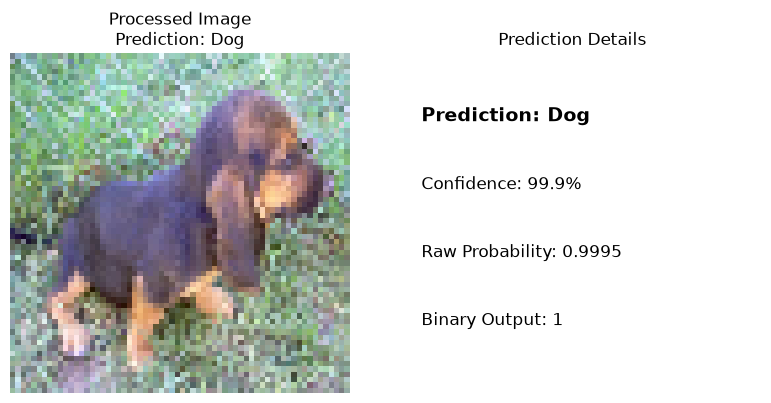

In [16]:
import matplotlib.pyplot as plt

# Display the processed image
plt.figure(figsize=(8, 4))

# Show the image that was fed to the model
plt.subplot(1, 2, 1)
plt.imshow(image[0])  # Remove batch dimension for display
plt.title(f"Processed Image\nPrediction: {predicted_class}")
plt.axis('off')

# Show prediction details
plt.subplot(1, 2, 2)
plt.text(0.1, 0.8, f"Prediction: {predicted_class}", fontsize=14, fontweight='bold')
plt.text(0.1, 0.6, f"Confidence: {confidence*100:.1f}%", fontsize=12)
plt.text(0.1, 0.4, f"Raw Probability: {prediction[0][0]:.4f}", fontsize=12)
plt.text(0.1, 0.2, f"Binary Output: {binary_prediction[0][0]}", fontsize=12)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.axis('off')
plt.title("Prediction Details")

plt.tight_layout()
plt.show()

## Step 12: Create a Prediction Function
Let's create a reusable function that can predict on any image. This makes it easy to test multiple images without repeating all the preprocessing steps.


In [17]:
def predict_cat_or_dog(image_path, model):
    """
    Predict whether an image contains a cat or dog
    
    Args:
        image_path (str): Path to the image file
        model: Pre-trained CNN model
    
    Returns:
        dict: Prediction results including class, confidence, and probability
    """
    try:
        # Load and preprocess image
        image = cv2.imread(image_path)
        if image is None:
            return {"error": "Could not load image. Check file path."}
        
        # Convert BGR to RGB
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        # Resize to 64x64
        image = cv2.resize(image, (64, 64))
        
        # Normalize pixel values
        image = image * (1/255.0)
        
        # Add batch dimension
        image = np.array([image])

        #image_shape -- 10,64,64,3
        
        # Make prediction
        prediction = model.predict(image, verbose=False)
        
        # Convert to binary
        binary_pred = prediction > 0.5
        binary_pred = binary_pred.astype("int")
        
        # Determine class and confidence
        predicted_class = "Dog" if binary_pred[0][0] == 1 else "Cat"
        confidence = prediction[0][0] if binary_pred[0][0] == 1 else 1 - prediction[0][0]
        
        return {
            "class": predicted_class,
            "confidence": confidence,
            "probability": prediction[0][0],
            "binary": binary_pred[0][0]
        }
    
    except Exception as e:
        return {"error": f"Prediction failed: {str(e)}"}

## Step 13: Test the Prediction Function
Now let's test our function with the same image to make sure it works correctly. You can easily test it with different images by changing the path.


In [20]:
# Test the prediction function

image_path = "dog_2.jpg"
result = predict_cat_or_dog(image_path, cnn_model)

if "error" in result:
    print(f"Error: {result['error']}")
else:
    print("=== Prediction Results ===")
    print(f"Predicted Class: {result['class']}")
    print(f"Confidence: {result['confidence']:.4f} ({result['confidence']*100:.1f}%)")
    print(f"Raw Probability: {result['probability']:.4f}")
    print(f"Binary Output: {result['binary']}")
    
    # Interpretation
    if result['confidence'] > 0.8:
        print("🎯 High confidence prediction!")
    elif result['confidence'] > 0.6:
        print("✅ Good confidence prediction")
    else:
        print("⚠️ Low confidence prediction - model is uncertain")

=== Prediction Results ===
Predicted Class: Dog
Confidence: 1.0000 (100.0%)
Raw Probability: 1.0000
Binary Output: 1
🎯 High confidence prediction!


## Step 14: Try Multiple Images


### Task -- 
1. Create a function to load and predict multiple image at once

## Congratulations! 🎉

You've successfully learned how to use a pre-trained CNN model to make predictions on new images! Here's what you accomplished:

### What You Learned:
1. **Model Loading**: How to load a pre-trained CNN model from a saved file
2. **Image Preprocessing**: Complete pipeline for preparing images for prediction
3. **Prediction Process**: How to make predictions and interpret results
4. **Function Creation**: Built a reusable function for easy prediction on any image

### Key Skills Developed:
- **Image Processing**: Converting color formats, resizing, and normalizing images
- **Model Deployment**: Using trained models for real-world predictions
- **Result Interpretation**: Understanding confidence scores and probability outputs
- **Error Handling**: Dealing with file loading issues and prediction errors

### Important Concepts:
- **Preprocessing Pipeline**: Images must be processed exactly like training data
- **Batch Dimension**: Neural networks expect data in batches (even single images)
- **Confidence Scores**: Higher confidence means the model is more certain
- **Threshold Values**: Using 0.5 as the decision boundary between classes

### Next Steps:
- Test your model on your own cat and dog images
- Try images with different lighting, angles, or backgrounds
- Experiment with different confidence thresholds
- Build a simple web app or GUI to make predictions easier
- Try retraining the model with more data for better accuracy

### Tips for Better Predictions:
- Use clear, well-lit images
- Ensure the animal is clearly visible in the image
- Try images similar to your training data
- Consider the model's limitations (it was trained on 64x64 images)

Keep experimenting and happy predicting! 🐱🐶
